# 2.0 Attributions methods comaprision

Here we comapre the various attribution methods on the AVFSpoof dataset.


In [7]:
import json
from pathlib import Path

import pandas as pd
import torch

from xai_bench.attributions.grad_cam import grad_cam
from xai_bench.attributions.integrated_gradients import integrated_gradients
from xai_bench.attributions.occlusion import occlusion
from xai_bench.attributions.smoothgrad_squared import smoothgrad_squared
from xai_bench.config import AttributionConfig, PrepareDataConfig
from xai_bench.models.resnet import ResNet18Detector
from xai_bench.plots import plot_attribution
from xai_bench.utils import get_device

root = Path("..")
cfg = AttributionConfig.from_yaml(root / "configs/attributions.yaml")
audio_cfg = PrepareDataConfig.from_yaml(root / "configs/prepare_data.yaml").audio

metadata = json.loads((root / cfg.processed_dir / "metadata.json").read_text())

torch.manual_seed(cfg.seed)
device = get_device()
model = ResNet18Detector.load_from_checkpoint(root / cfg.checkpoint_path, map_location=device).to(device).eval()

## Example maps


In [8]:
from xai_bench.data.dataset import PlantedAudioDataset

split = "test.pt"
dataset = PlantedAudioDataset(root / cfg.processed_dir / split)

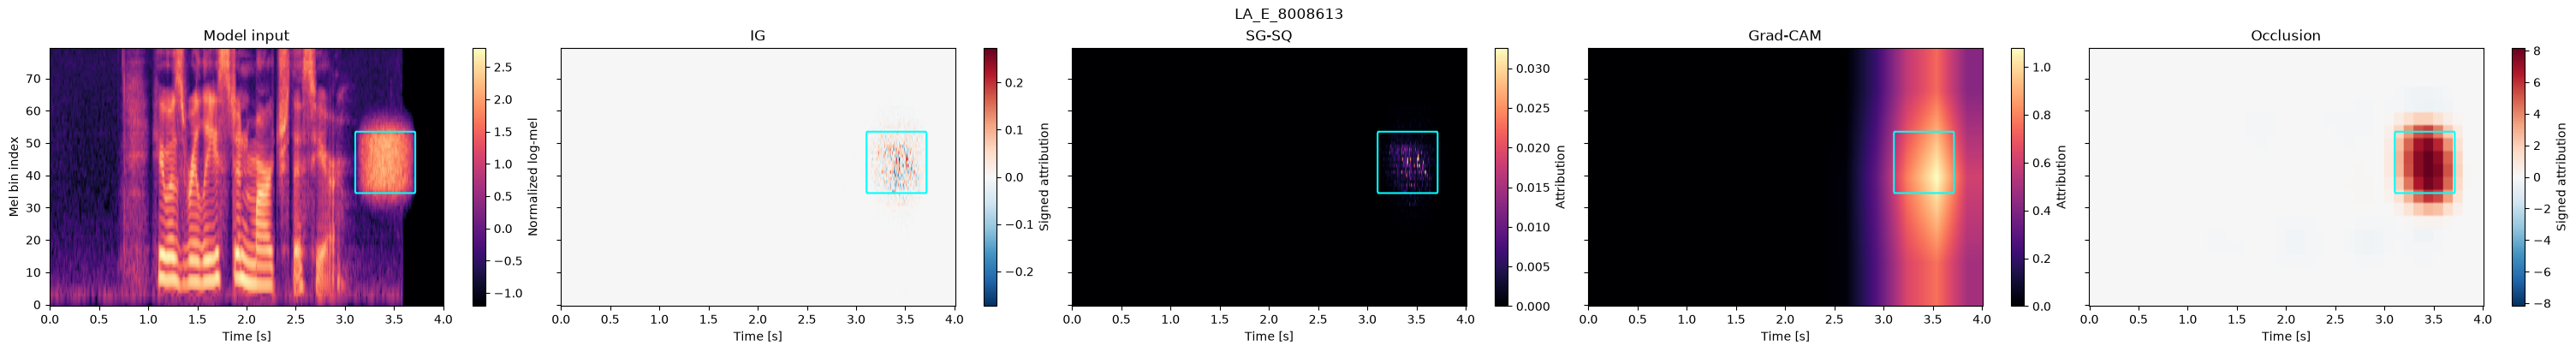

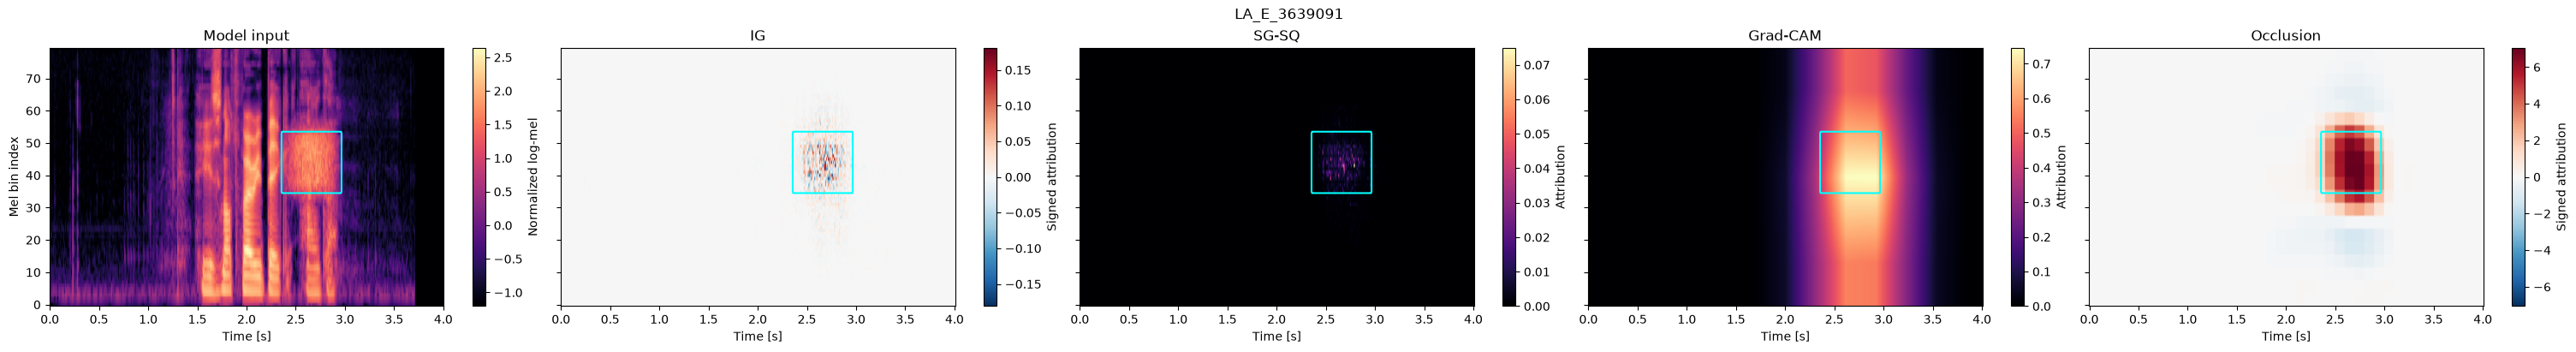

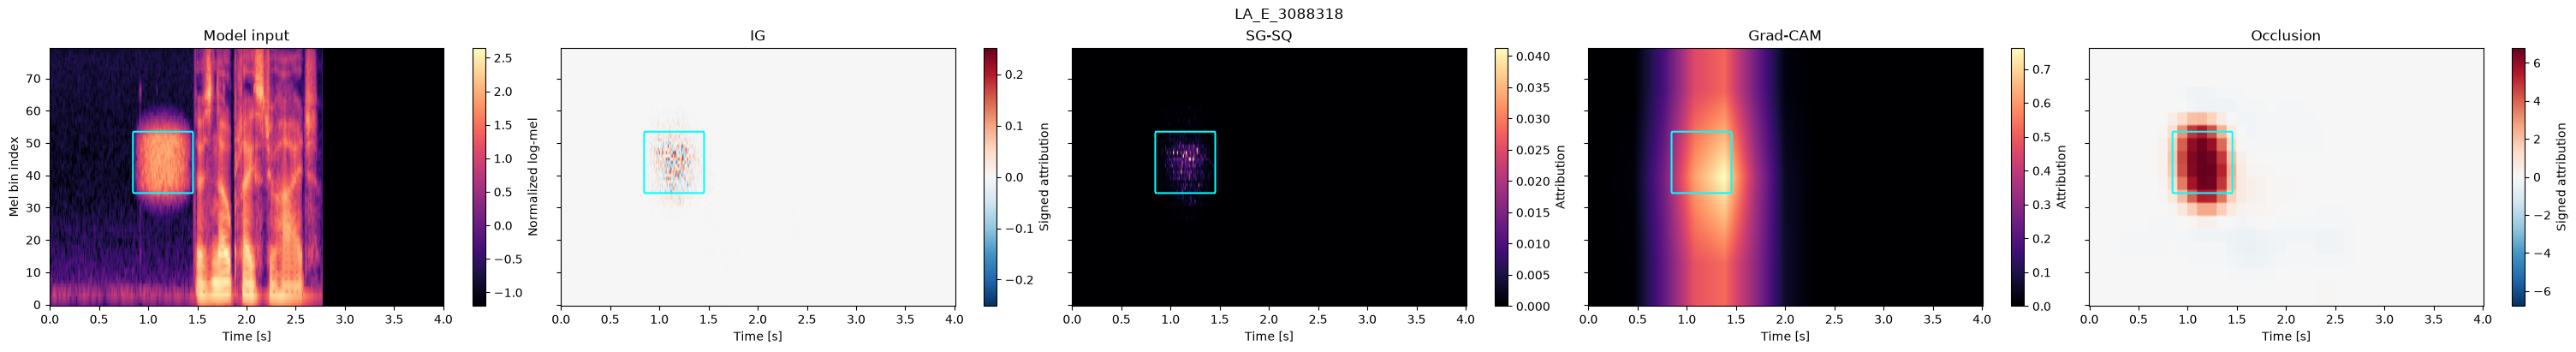

In [9]:
num_examples = 3
examples = [dataset[int(idx)] for idx in torch.where(dataset.labels == 1)[0][:num_examples]]

for sample in examples:
    spec = sample["spec"].unsqueeze(0).to(device)
    ig, _ = integrated_gradients(
        model,
        spec,
        metadata["normalized_silence_value"],
        n_steps=cfg.integrated_gradients.steps,
        internal_batch_size=cfg.integrated_gradients.batch_size,
    )
    sg = smoothgrad_squared(
        model,
        spec,
        n_samples=cfg.smoothgrad_squared.samples,
        stdev=cfg.smoothgrad_squared.stdev,
        batch_size=cfg.smoothgrad_squared.batch_size,
    )
    cam = grad_cam(model, spec, layer=cfg.grad_cam.layer)
    occ = occlusion(
        model, spec, metadata["normalized_silence_value"],
        window=cfg.occlusion.window, stride=cfg.occlusion.stride, batch_size=cfg.occlusion.batch_size,
    )
    plot_attribution(
        spec,
        {"IG": ig, "SG-SQ": sg, "Grad-CAM": cam, "Occlusion": occ},
        audio_cfg,
        gt_mask=sample["gt_mask"],
        title=sample["clip_id"],
    )


## Metrics

In [10]:
results = json.loads((root / cfg.output_dir / "metrics.json").read_text())
summary = pd.DataFrame.from_dict(results["summary"], orient="index").rename(
    columns={
        "gt_recovery": "GT Recovery ↑",
        "deletion_silence_auc": "Deletion AUC (silence) ↓",
        "deletion_mean_auc": "Deletion AUC (mean) ↓",
        "deletion_noise_auc": "Deletion AUC (noise) ↓",
        "insertion_silence_auc": "Insertion AUC (silence) ↑",
        "insertion_mean_auc": "Insertion AUC (mean) ↑",
        "insertion_noise_auc": "Insertion AUC (noise) ↑",
    }
)
summary.round(4).T

,IG,SG-SQ,Grad-CAM,Occlusion,Random
GT Recovery ↑,0.6159,0.8207,0.1584,0.5789,0.0362
Deletion AUC (silence) ↓,0.0287,0.0290,0.0270,0.0331,0.0296
Deletion AUC (mean) ↓,0.0264,0.0264,0.0266,0.0267,0.0260
Deletion AUC (noise) ↓,0.0465,0.0297,0.0788,0.0532,0.0290
Insertion AUC (silence) ↑,0.7248,0.9623,0.9392,0.9644,0.0295
Insertion AUC (mean) ↑,0.7964,0.9606,0.9165,0.9564,0.0260
Insertion AUC (noise) ↑,0.8646,0.9707,0.9578,0.9653,0.0290


## Deletion and insertion curves


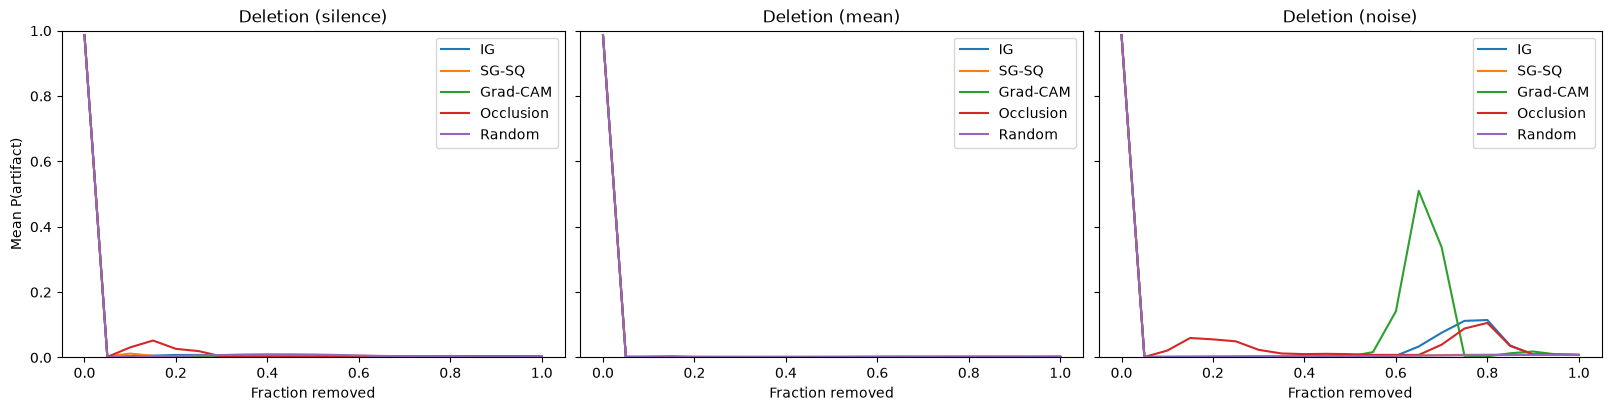

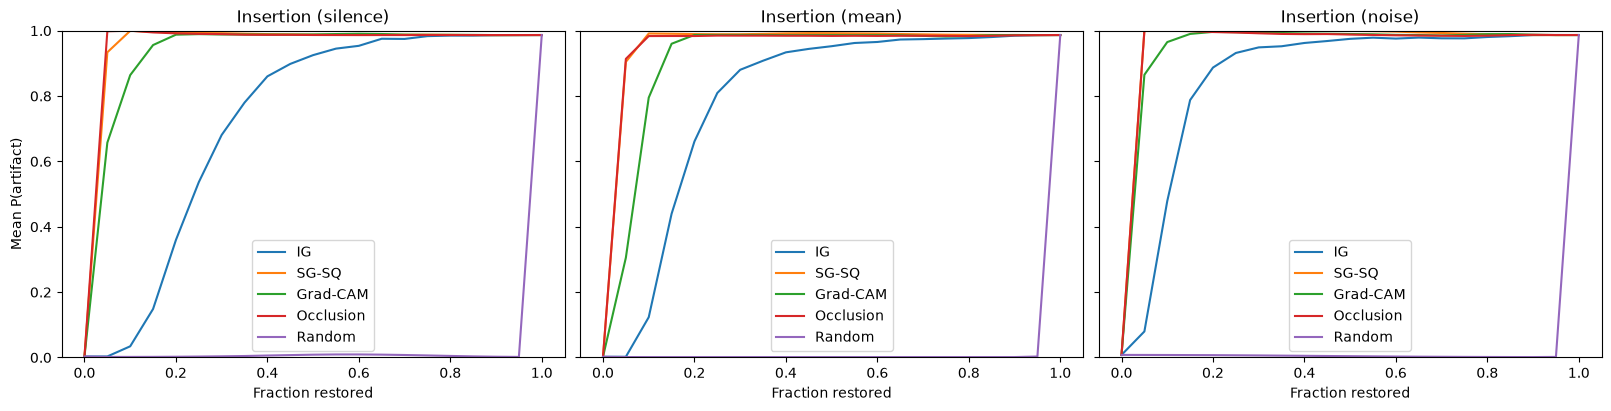

In [11]:
from xai_bench.plots import plot_perturbation_curves

plot_perturbation_curves(results, "deletion");
plot_perturbation_curves(results, "insertion");